# MuJoCo + robosuite Tutorial: Human-Robot Handover
### 1.5-Hour Lecture Notebook

---

**What you will learn:**
1. What MuJoCo and robosuite are, and how the environment works
2. How to read observations (robot state, object state, camera images)
3. How to apply actions and control the robot
4. How to render camera views and save episode videos
5. How to define and customize reward functions
6. How to train a reinforcement learning (RL) policy
7. How to evaluate and visualize a trained policy

**The Task:** One robot arm starts already holding a hammer and hands it to a person. The handle center must stay inside 2 cm of the palm-sphere center for 3 seconds, no faster than 5 mm/s, without touching the person.

| Section | Topic | Duration |
|---|---|---|
| Part 0 | Setup | 5 min |
| Part 1 | Creating the environment | 10 min |
| Part 2 | Observations | 15 min |
| Part 3 | Actions | 10 min |
| Part 4 | Rendering & video recording | 10 min |
| Part 5 | Reward functions | 15 min |
| Part 6 | Training an RL policy | 20 min |
| Part 7 | Evaluation & visualization | 15 min |

---


## Part 0 — Setup

Before we start, make sure the robosuite repo is on the Python path. Run this notebook from the CourseProj directory. The library is `mujoco/robosuite`.


In [1]:
from pathlib import Path
import sys

# Point Python at the local robosuite clone
NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR / "mujoco" / "robosuite"
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import imageio.v2 as imageio
import matplotlib.pyplot as plt
from IPython.display import Video, display

import robosuite as suite

print("robosuite version:", suite.__version__)
print("numpy version:", np.__version__)


[robosuite WARNING] No private macro file found! (macros.py:57)
[robosuite WARNING] It is recommended to use a private macro file (macros.py:58)
[robosuite WARNING] To setup, run: python /Users/renton/Desktop/Repository/CourseProj/mujoco/robosuite/robosuite/scripts/setup_macros.py (macros.py:59)
[robosuite WARNING] Could not load the mink-based whole-body IK. Make sure you install related import properly (e.g. pip install mink==0.0.5), otherwise you will not be able to use the default IK controller setting for GR1 robot. (__init__.py:42)


robosuite version: 1.5.2
numpy version: 2.4.4


---
## Part 1 — Creating the Environment

### 1.1 What is MuJoCo?

**MuJoCo** (Multi-Joint dynamics with Contact) is a physics simulator. It models rigid bodies, joints, contacts, and actuators.

**robosuite** is a robotics library built on top of MuJoCo. It provides:
- Ready-made robot arms (Panda, XArm7, UR5e, ...)
- Ready-made manipulation tasks (Lift, Pick-and-Place, Assembly, ...)
- Cameras, sensors, and a standard observation / action interface

The interface follows the classic **Gym loop**:

```
obs = env.reset()                        # start a new episode
obs, reward, done, info = env.step(action)   # advance one timestep
```

### 1.2 The human-robot handover task

```
  Robot  ——  table  ——  person
           [hammer already in the gripper]
           [yellow palm sphere in front of the hand]
```

- One **XArm7** starts with the hammer head already pinched.
- A **person** stands on the far side of the table, palm facing the robot.
- The yellow **palm sphere** is the target. Its center sits 6 cm out from the hand.
- **Goal**: keep the handle center within **2 cm** of the sphere center for **3 seconds** (60 steps at 20 Hz), at **5 mm/s** or slower.
- Touching the person, including the hand, ends the episode on that step.

### 1.3 Creating the environment


In [2]:
env = suite.make(
    env_name="HumanRobotHandover",  # which task to load
    robots="XArm7Handover",         # one XArm7

    # --- Rendering ---
    has_renderer=False,             # no pop-up window (headless)
    has_offscreen_renderer=True,    # render to image buffers instead
    use_camera_obs=True,            # include camera images in observations
    camera_names=["agentview", "robot0_eye_in_hand"],
    camera_heights=256,
    camera_widths=256,

    # --- Reward ---
    reward_shaping=False,           # sparse reward for now (1 on success, 0 otherwise)
    reward_scale=1.0,

    # --- Episode length ---
    horizon=300,                    # max timesteps per episode (15 s at 20 Hz)
    control_freq=20,                # 20 Hz control (50 ms per step)

    # The held grasp was measured on the seed-0 hammer.
    initialization_noise=None,
    seed=0,
    hard_reset=False,
)
# The episode starts with the hammer already in the gripper.
env.start_holding = True

print("Environment created successfully!")
print("Type:", type(env).__name__)


[robosuite INFO] Loading controller configuration from: /Users/renton/Desktop/Repository/CourseProj/mujoco/robosuite/robosuite/controllers/config/robots/default_xarm7handover.json (composite_controller_factory.py:121)


Environment created successfully!
Type: HumanRobotHandover


**Key parameters explained:**

| Parameter | What it does |
|---|---|
| `env_name` | Selects the task class |
| `robots` | Robot model. This task uses one arm, `XArm7Handover` |
| `has_renderer` | `True` opens an interactive on-screen viewer |
| `has_offscreen_renderer` | `True` renders to in-memory image arrays |
| `use_camera_obs` | Adds camera images to the observation dict |
| `horizon` | Episode ends after this many timesteps |
| `control_freq` | How many times per second the policy can issue actions |
| `reward_shaping` | `True` uses the dense handover reward instead of the sparse success reward |
| `start_holding` | Set on the environment after `suite.make`. The hammer starts in the gripper |


---
## Part 2 — Observations

After calling `env.reset()` or `env.step(action)`, you receive an **observation dictionary**.
Each key maps to a numpy array.

### 2.1 Listing all observation keys


In [3]:
obs = env.reset()

print(f"{'Key':<40} {'Shape':<15} {'dtype'}")
print("-" * 65)
for key, val in obs.items():
    arr = np.asarray(val)
    print(f"{key:<40} {str(arr.shape):<15} {arr.dtype}")


Key                                      Shape           dtype
-----------------------------------------------------------------
robot0_joint_pos                         (7,)            float64
robot0_joint_pos_cos                     (7,)            float64
robot0_joint_pos_sin                     (7,)            float64
robot0_joint_vel                         (7,)            float64
robot0_joint_acc                         (7,)            float64
robot0_eef_pos                           (3,)            float64
robot0_eef_quat                          (4,)            float64
robot0_eef_quat_site                     (4,)            float32
robot0_gripper_qpos                      (6,)            float64
robot0_gripper_qvel                      (6,)            float64
agentview_image                          (256, 256, 3)   uint8
robot0_eye_in_hand_image                 (256, 256, 3)   uint8
hammer_quat                              (4,)            float64
handle_pos                    

### 2.2 Robot proprioception — joint states and end-effector pose

The arm exposes:
- **`robot0_joint_pos`** — 7 joint angles (radians)
- **`robot0_joint_vel`** — 7 joint velocities (rad/s)
- **`robot0_eef_pos`** — 3D position of the end-effector (meters)
- **`robot0_eef_quat`** — orientation as quaternion `[x, y, z, w]`
- **`robot0_gripper_qpos`** — gripper finger positions


In [4]:
print("=== Robot 0 ===")
print("Joint positions (rad):  ", np.round(obs["robot0_joint_pos"], 3))
print("Joint velocities (r/s): ", np.round(obs["robot0_joint_vel"], 3))
print("EEF position (m):       ", np.round(obs["robot0_eef_pos"], 4))
print("EEF quaternion (xyzw):  ", np.round(obs["robot0_eef_quat"], 4))
print("Gripper finger qpos:    ", np.round(obs["robot0_gripper_qpos"], 4))


=== Robot 0 ===
Joint positions (rad):   [0.    0.    0.    1.225 0.    1.225 0.   ]
Joint velocities (r/s):  [0. 0. 0. 0. 0. 0. 0.]
EEF position (m):        [-0.     -0.333   1.2119]
EEF quaternion (xyzw):   [ 0.7071 -0.7071 -0.     -0.    ]
Gripper finger qpos:     [0.5033 0.5431 0.4947 0.5042 0.5222 0.5003]


### 2.3 Object state — hammer and palm

These are task-specific observations. The palm-sphere center is not in `obs`. It arrives in `info` after `env.step()`, under `ellipsoid_pos`.


In [5]:
print("Handle position (m):   ", np.round(obs["handle_pos"], 4))
print("Hammer-head position:  ", np.round(obs["head_pos"], 4))
print("Right-wrist position:   ", np.round(obs["palm_pos"], 4))
print("Hammer quaternion:     ", np.round(obs["hammer_quat"], 4))
print("Hammer velocity (m/s): ", np.round(obs["hammer_vel"], 4))

low, high = env.action_spec
obs, reward, done, info = env.step(np.zeros(low.shape))
center_dist = np.linalg.norm(obs["handle_pos"] - info["ellipsoid_pos"])
print()
print("Palm-sphere center (m):", np.round(info["ellipsoid_pos"], 4))
print(f"Handle to sphere center: {center_dist:.4f} m")
print("Hold ball: 0.02 m. Hold speed: 0.005 m/s. Hold time: 60 steps.")


Handle position (m):    [ 0.0894 -0.3456  1.1662]
Hammer-head position:   [-0.0018 -0.34    1.1689]
Right-wrist position:    [-0.0095  0.04    1.293 ]
Hammer quaternion:      [ 0.4764 -0.5083 -0.5217  0.4925]
Hammer velocity (m/s):  [0. 0. 0.]

Palm-sphere center (m): [ 0.0119 -0.0529  1.3184]
Handle to sphere center: 0.3389 m
Hold ball: 0.02 m. Hold speed: 0.005 m/s. Hold time: 60 steps.


**Summary of task-specific observation keys:**

| Key | Shape | Meaning |
|---|---|---|
| `handle_pos` | (3,) | XYZ of the hammer handle center |
| `head_pos` | (3,) | XYZ of the hammer head |
| `palm_pos` | (3,) | XYZ of the right wrist mesh, not the palm sphere |
| `hammer_quat` | (4,) | Hammer orientation |
| `hammer_vel` | (3,) | Hammer linear velocity (m/s) |

The score also reads `info`, filled by `env.step()`:

| Key | Meaning |
|---|---|
| `ellipsoid_pos` | Center of the palm sphere (meters) |
| `hammer_speed` | Hammer linear speed (m/s) |
| `hold_steps` | Steps in a row inside 2 cm and at most 5 mm/s |
| `body_contact` | 1 if the hammer or the arm touches the person outside the right hand |
| `hand_contact` | 1 if the hammer or the arm touches the right hand |
| `success` | 1 after 60 hold steps |
| `failure` | 1 if the person was touched on this step |

**Success condition:** `hold_steps` reaches 60. Touching the person sets `failure` and cannot also succeed.


### 2.4 Camera images

Camera images are numpy arrays of shape `(H, W, 3)` with uint8 pixel values in `[0, 255]`.

> **Note:** robosuite images are stored upside-down internally. Always apply `[::-1]` to flip them right-side-up before displaying or saving.


In [7]:
# Check image shapes
for cam in ["agentview", "robot0_eye_in_hand"]:
    img = obs[f"{cam}_image"]
    print(f"{cam}_image: shape={img.shape}, dtype={img.dtype}")


agentview_image: shape=(256, 256, 3), dtype=uint8
robot0_eye_in_hand_image: shape=(256, 256, 3), dtype=uint8


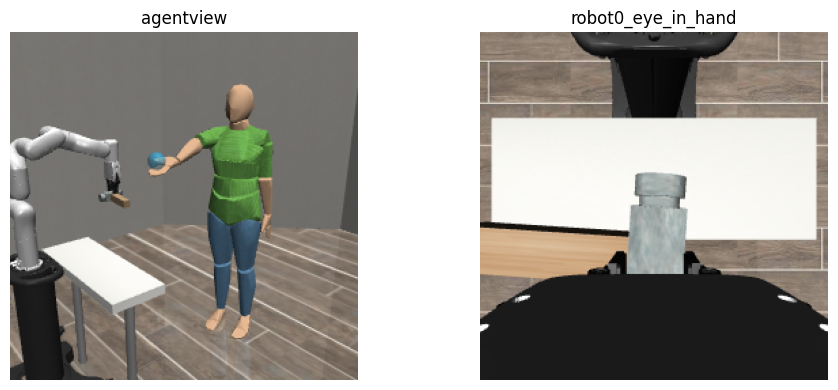

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, cam in zip(axes, ["agentview", "robot0_eye_in_hand"]):
    ax.imshow(obs[f"{cam}_image"][::-1])
    ax.set_title(cam)
    ax.axis("off")
plt.tight_layout()
plt.show()


---
## Part 3 — Actions

### 3.1 Understanding the action space

Actions are a flat numpy array. This arm uses an operational-space controller, so the action is a pose increment plus the gripper:

```
action = [ dx, dy, dz, droll, dpitch, dyaw, gripper ]
                                              total = 7 dimensions
```

- Commands are in `[-1, 1]`. A full position command moves the end-effector **2 cm**. A full rotation command turns it **0.02 rad**. Both apply over one 20 Hz step.
- **Gripper command**: `+1.0` = open fully, `-1.0` = close fully. The episode starts already holding, and the fingers stay closed.
- `env.action_spec` returns `(low, high)` bound arrays


In [9]:
low, high = env.action_spec
print("Action dimension:", low.shape[0])
print("Lower bounds:", np.round(low, 2))
print("Upper bounds:", np.round(high, 2))

print()
print("Position:  indices 0-2   (dx, dy, dz)")
print("Rotation:  indices 3-5   (droll, dpitch, dyaw)")
print("Gripper:   index 6       (+1=open, -1=close)")


Action dimension: 7
Lower bounds: [-1. -1. -1. -1. -1. -1. -1.]
Upper bounds: [1. 1. 1. 1. 1. 1. 1.]

Position:  indices 0-2   (dx, dy, dz)
Rotation:  indices 3-5   (droll, dpitch, dyaw)
Gripper:   index 6       (+1=open, -1=close)


### 3.2 Zero action — the robot holds position


In [10]:
obs = env.reset()

zero_action = np.zeros(low.shape)
obs, reward, done, info = env.step(zero_action)

print(f"reward = {reward:.4f}")
print(f"done   = {done}")
print(f"info keys: {list(info.keys())}")
print()
print(f"success:       {info.get('success', 0)}")
print(f"failure:       {info.get('failure', 0)}")
print(f"body_contact:  {info.get('body_contact', 0)}")
print(f"hand_contact:  {info.get('hand_contact', 0)}")
print(f"hammer_speed:  {info.get('hammer_speed', 0):.4f} m/s")
print(f"hold_steps:    {info.get('hold_steps', 0):.0f}")
center_dist = np.linalg.norm(np.asarray(info["handle_pos"]) - np.asarray(info["ellipsoid_pos"]))
print(f"handle→sphere: {center_dist:.4f} m")


reward = 0.0000
done   = False
info keys: ['success', 'failure', 'body_contact', 'hand_contact', 'handle_pos', 'ellipsoid_pos', 'hammer_speed', 'hold_steps']

success:       0.0
failure:       0.0
body_contact:  0.0
hand_contact:  0.0
hammer_speed:  0.0002 m/s
hold_steps:    0
handle→sphere: 0.3389 m


### 3.3 Random actions

Random actions thrash the robot around. Useful for sanity-checking the environment and generating exploration data.


Total reward over 100 random steps: 0.0000
Did we succeed? False


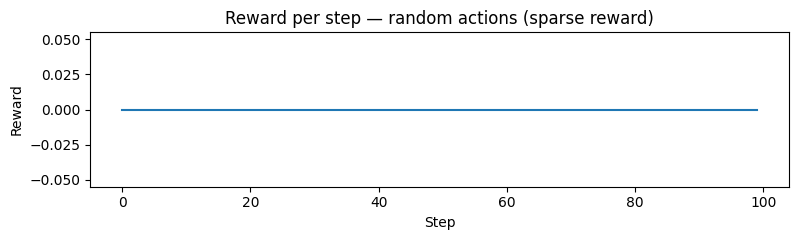

In [11]:
obs = env.reset()
total_reward = 0.0
rewards_per_step = []

for step in range(100):
    action = np.random.uniform(low, high)         # sample uniformly in [low, high]
    obs, reward, done, info = env.step(action)
    total_reward += reward
    rewards_per_step.append(reward)
    if done:
        print(f"Episode finished early at step {step}")
        break

print(f"Total reward over {step+1} random steps: {total_reward:.4f}")
print("Did we succeed?", bool(info.get("success", False)))

plt.figure(figsize=(8, 2.5))
plt.plot(rewards_per_step)
plt.xlabel("Step")
plt.ylabel("Reward")
plt.title("Reward per step — random actions (sparse reward)")
plt.tight_layout()
plt.show()


---
## Part 4 — Rendering and Saving Videos

### 4.1 Saving a single frame


Saved frame_reset.png  shape=(256, 256, 3)


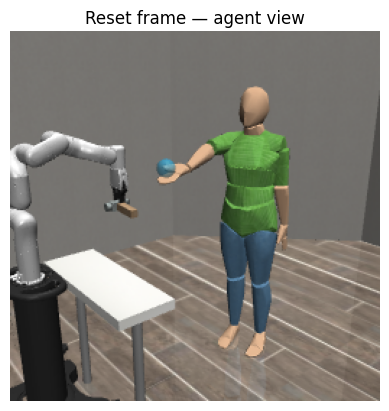

In [12]:
obs = env.reset()

# Grab the agent-view image and flip it upright
frame = obs["agentview_image"][::-1]

imageio.imwrite("frame_reset.png", frame)
print(f"Saved frame_reset.png  shape={frame.shape}")

plt.imshow(frame)
plt.axis("off")
plt.title("Reset frame — agent view")
plt.show()


### 4.2 Recording an episode video

We collect frames during an episode and write them to an MP4 using `imageio`.


In [13]:
def record_episode(env, policy_fn, video_path, camera="agentview", fps=20, max_steps=300):
    """
    Run one episode using `policy_fn(obs)` and save a video.

    Args:
        env        : robosuite environment
        policy_fn  : callable(obs_dict) -> action (numpy array)
        video_path : output .mp4 path (str or Path)
        camera     : which camera to record
        fps        : frames per second in the output video
        max_steps  : stop recording after this many steps

    Returns:
        (total_reward, n_steps)
    """
    obs = env.reset()
    total_reward = 0.0
    frames = [obs[f"{camera}_image"][::-1]]   # first frame at reset

    for step in range(max_steps):
        action = policy_fn(obs)
        obs, reward, done, info = env.step(action)
        frames.append(obs[f"{camera}_image"][::-1])
        total_reward += reward
        if done:
            break

    # Write video file
    with imageio.get_writer(str(video_path), fps=fps) as writer:
        for f in frames:
            writer.append_data(f)

    return total_reward, len(frames)


# A simple random policy
def random_policy(obs):
    """Ignore obs, return a random action within bounds."""
    return np.random.uniform(low, high)


reward, n_frames = record_episode(
    env,
    policy_fn=random_policy,
    video_path="random_policy.mp4",
    camera="agentview",
    fps=20,
    max_steps=200,
)
print(f"Saved random_policy.mp4  ({n_frames} frames, total reward={reward:.3f})")


Saved random_policy.mp4  (201 frames, total reward=0.000)


In [14]:
# Play the video inline in the notebook
display(Video("random_policy.mp4", embed=True, width=400))


### 4.3 Recording multiple camera views side-by-side


In [15]:
def record_multi_camera(env, policy_fn, video_path, cameras, fps=20, max_steps=200):
    """Record multiple cameras tiled horizontally into a single video."""
    obs = env.reset()

    def tile_cameras(ob):
        return np.concatenate([ob[f"{c}_image"][::-1] for c in cameras], axis=1)

    frames = [tile_cameras(obs)]
    for _ in range(max_steps):
        obs, _, done, _ = env.step(policy_fn(obs))
        frames.append(tile_cameras(obs))
        if done:
            break

    with imageio.get_writer(str(video_path), fps=fps) as writer:
        for f in frames:
            writer.append_data(f)

    print(f"Saved {video_path}  ({len(frames)} frames)")


record_multi_camera(
    env,
    policy_fn=random_policy,
    video_path="random_multi_cam.mp4",
    cameras=["agentview", "robot0_eye_in_hand"],
)
display(Video("random_multi_cam.mp4", embed=True, width=700))


Saved random_multi_cam.mp4  (201 frames)


---
## Part 5 — Reward Functions

The reward is the **learning signal** — it tells the RL algorithm what we want the robot to do.

### 5.1 The built-in sparse reward

With `reward_shaping=False` (current setting):
- `reward = 1.0` on the step that completes the 3 second hold
- `reward = 0.0` otherwise, including a step that touches the person

**Problem:** The arm almost never stays inside 2 cm at 5 mm/s for 3 seconds by chance, so the sparse reward provides almost no useful gradient for learning.

### 5.2 The built-in dense reward

With `reward_shaping=True` the environment scores every step from the handle, the palm sphere, and the hammer speed. Every term is zero or positive. Touching the person sets `failure` and ends the episode.

```
# 1 at the sphere center, falling toward 0. 0.15 m is the decay length.
distance_score = exp(-(distance / 0.15) ** 2)          # gaussian

reward = distance_score
       + 1  if distance <= 2 cm                        # any speed
       + distance_score * 0.003 / max(speed, 0.003)    # slower pays more
       + 1  if distance <= 2 cm and speed <= 5 mm/s
       + 10 on the 60th such step in a row
```

The custom-reward cell prints this distance score at 0, 5, 10, 20, 35, and 70 cm.

Let's create a dense-reward environment and plot the reward during random exploration:


[robosuite INFO] Loading controller configuration from: /Users/renton/Desktop/Repository/CourseProj/mujoco/robosuite/robosuite/controllers/config/robots/default_xarm7handover.json (composite_controller_factory.py:121)


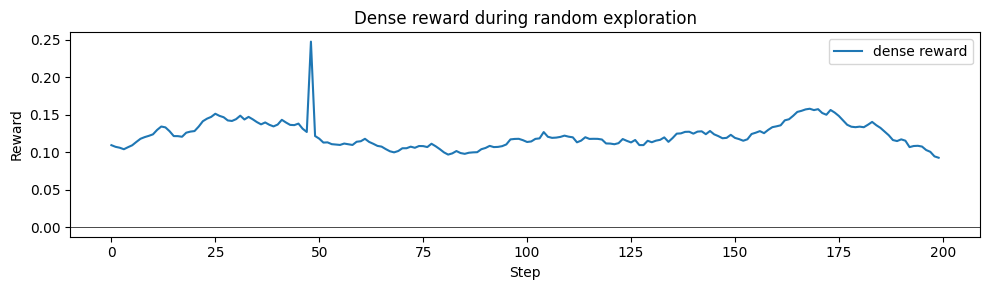

Mean dense reward: 0.1228
Reward range: [0.0928, 0.2475]


In [16]:
env_dense = suite.make(
    env_name="HumanRobotHandover",
    robots="XArm7Handover",
    has_renderer=False,
    has_offscreen_renderer=False,  # no camera needed for reward comparison
    use_camera_obs=False,
    reward_shaping=True,           # <-- dense reward
    horizon=300,
    control_freq=20,
    initialization_noise=None,
    seed=0,
    hard_reset=False,
)
env_dense.start_holding = True

low_d, high_d = env_dense.action_spec

obs_d = env_dense.reset()
dense_rewards = []
for _ in range(200):
    obs_d, r, done, _ = env_dense.step(np.random.uniform(low_d, high_d))
    dense_rewards.append(r)
    if done:
        obs_d = env_dense.reset()

env_dense.close()

plt.figure(figsize=(10, 3))
plt.plot(dense_rewards, label="dense reward")
plt.axhline(0, color="k", linewidth=0.5)
plt.xlabel("Step")
plt.ylabel("Reward")
plt.title("Dense reward during random exploration")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Mean dense reward: {np.mean(dense_rewards):.4f}")
print(f"Reward range: [{min(dense_rewards):.4f}, {max(dense_rewards):.4f}]")


### 5.3 The current reward

Running the cell prints the distance score at 0, 5, 10, 20, 35, and 70 cm. `prepare_reward` reads the step and computes that score. That part is already written. The reward inside `custom_reward`, below the marker, is the part to write. `obs` is not used. Every term is zero or positive. Touching the person sets `failure` and ends the episode.


In [18]:
def prepare_reward(info):
    """Read one step. This is preparation, not the reward students write.

    distance        Meters from the handle center to the palm-sphere center.
    speed           Hammer linear speed, meters per second.
    hold_steps      Steps in a row inside 2 cm at no more than 5 mm/s.
    distance_score  Reward for the corresponding distance.
    """
    distance = float(np.linalg.norm(info["handle_pos"] - info["ellipsoid_pos"]))
    speed = float(info["hammer_speed"])
    hold_steps = info["hold_steps"]

    distance_score = float(np.exp(-(distance / 0.15) ** 2))

    return distance, speed, hold_steps, distance_score


def custom_reward(info):
    """
    Use the values returned by prepare_reward() to write your own reward.
    Stage 1: Enter the 5 cm target zone by the end of an episode.
    Stage 2: Enter the 2 cm target zone and stay inside for hold_steps = 60 (about 3 s) within an episode.
    Stage 3: Fulfill stages 1 and 2, and also keep the hammer speed lower than 5 mm/s.
    """
    distance, speed, hold_steps, distance_score = prepare_reward(info)

    # --- reward: write from here ---
    # 3 seconds at 20 Hz.
    reward = distance_score

    # Inside 2 cm, any speed.
    if distance <= 0.02:
        reward = reward + 1.0

    # Full at 3 mm/s or slower. Faster still pays, as 3 mm/s divided by the speed.
    reward = reward + distance_score * 0.003 / max(speed, 0.003)

    # Inside 2 cm and no faster than 5 mm/s. The 60th step in a row pays 10 more.
    if distance <= 0.02 and speed <= 0.005:
        reward = reward + 1.0
        if hold_steps >= 60:
            reward = reward + 10.0
    return float(reward)


obs = env.reset()
obs, env_r, done, info = env.step(np.zeros(low.shape))
my_r = custom_reward(info)
distance, speed, hold_steps, distance_score = prepare_reward(info)
chosen = "  ".join(
    f"{cm:>2}cm {prepare_reward({'handle_pos': np.array([cm / 100.0, 0.0, 0.0]), 'ellipsoid_pos': np.zeros(3), 'hammer_speed': 0.0, 'hold_steps': 0})[3]:.3f}"
    for cm in (0, 5, 10, 20, 35, 70)
)
print("distance_score at 0, 5, 10, 20, 35, 70 cm")
print(f"  {chosen}")
print(f"env_reward    = {env_r:.4f}")
print(f"custom_reward = {my_r:.4f}")
print(f"  distance: {distance_score:.3f}")
print(f"  inside:   {1.0 if distance <= 0.02 else 0.0:.3f}")
print(f"  speed:    {distance_score * 0.003 / max(speed, 0.003):.3f}")
print(f"  hold:     {1.0 if distance <= 0.02 and speed <= 0.005 else 0.0:.3f}")


distance_score at 0, 5, 10, 20, 35, 70 cm
   0cm 1.000   5cm 0.895  10cm 0.641  20cm 0.169  35cm 0.004  70cm 0.000
env_reward    = 0.0000
custom_reward = 0.0121
  distance: 0.006
  inside:   0.000
  speed:    0.006
  hold:     0.000


---
## Part 6 — Training an RL Policy

We use **Stable-Baselines3 (SB3)**, a reliable and well-documented RL library.

### 6.1 Gymnasium wrapper

SB3 expects the **Gymnasium** API:
- `obs, info = env.reset(seed=...)`
- `obs, reward, terminated, truncated, info = env.step(action)`

We write a thin wrapper that:
1. Converts robosuite's 4-return `step()` to Gymnasium's 5-return format
2. Flattens all non-image observations into a single vector
3. Applies our custom reward


In [ ]:
import gymnasium as gym
from gymnasium import spaces


class HandoverGymEnv(gym.Env):
    """
    Gymnasium wrapper around robosuite HumanRobotHandover.

    - Flattens all non-image observations into a 1-D float32 vector
    - Plugs in a custom reward function
    - Compatible with Stable-Baselines3
    """

    def __init__(self, reward_fn=None, horizon=300):
        super().__init__()

        # Build the underlying robosuite environment (no cameras needed for training)
        self._env = suite.make(
            env_name="HumanRobotHandover",
            robots="XArm7Handover",
            has_renderer=False,
            has_offscreen_renderer=False,
            use_camera_obs=False,
            reward_shaping=True,   # built-in dense reward as fallback
            horizon=horizon,
            control_freq=20,
            initialization_noise=None,
            seed=0,
            hard_reset=False,
        )
        self._env.start_holding = True
        self._reward_fn = reward_fn
        self._low, self._high = self._env.action_spec

        # Figure out the observation shape by doing a dummy reset
        dummy_obs = self._env.reset()
        self._obs_keys = sorted(
            k for k in dummy_obs.keys() if not k.endswith("_image")
        )
        flat_obs = self._flatten_obs(dummy_obs)

        # Define Gymnasium spaces
        self.observation_space = spaces.Box(
            low=-np.inf, high=np.inf, shape=flat_obs.shape, dtype=np.float32
        )
        self.action_space = spaces.Box(
            low=self._low.astype(np.float32),
            high=self._high.astype(np.float32),
            dtype=np.float32,
        )

    def _flatten_obs(self, obs):
        """Concatenate selected obs keys into a float32 vector."""
        parts = [np.asarray(obs[k], dtype=np.float32).ravel() for k in self._obs_keys]
        return np.concatenate(parts)

    def reset(self, *, seed=None, options=None):
        if seed is not None:
            np.random.seed(seed)
        obs = self._env.reset()
        return self._flatten_obs(obs), {}

    def step(self, action):
        obs, env_reward, done, info = self._env.step(action)

        # custom_reward(info) reads the step dict. obs is not an input.
        reward = self._reward_fn(info) if self._reward_fn else env_reward

        # Success ends the episode. Touching the person is the other ending,
        # so that step is not treated as a timeout.
        terminated = bool(info.get("success", False)) or bool(info.get("failure", False))
        truncated = bool(done) and not terminated

        return self._flatten_obs(obs), float(reward), terminated, truncated, info

    def render(self):
        pass  # headless during training

    def close(self):
        self._env.close()


# Sanity check
gym_env = HandoverGymEnv(reward_fn=custom_reward)
obs_flat, _ = gym_env.reset(seed=0)
print(f"Observation vector dim: {obs_flat.shape[0]}")
print(f"Action space:           {gym_env.action_space}")

obs_flat, r, terminated, truncated, info = gym_env.step(gym_env.action_space.sample())
print(f"Step — reward: {r:.4f}  terminated: {terminated}  truncated: {truncated}")
gym_env.close()


### 6.2 Training with SAC

**Algorithms overview:**

| Algorithm | Type | Good for |
|---|---|---|
| **PPO** | On-policy | Stable, easy to tune; good default |
| **SAC** | Off-policy | More sample-efficient; works well for continuous control |
| **TD3** | Off-policy | Deterministic policy; robust for robotic control |

We use **SAC** — it tends to be more sample-efficient for robotic manipulation.


In [ ]:
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import EvalCallback, CheckpointCallback
from stable_baselines3.common.monitor import Monitor

# Training and evaluation environments
train_env = Monitor(HandoverGymEnv(reward_fn=custom_reward, horizon=300))
eval_env  = Monitor(HandoverGymEnv(reward_fn=custom_reward, horizon=300))

# Callback: save best model and log evaluation performance
eval_callback = EvalCallback(
    eval_env=eval_env,
    best_model_save_path="./saved_models/handover_best_sac",
    log_path="./saved_models/handover_eval_logs",
    eval_freq=5000,
    n_eval_episodes=3,
    deterministic=True,
    verbose=1,
)

checkpoint_callback = CheckpointCallback(
    save_freq=10000,
    save_path="./saved_models/handover_checkpoints",
    name_prefix="sac_handover",
)

# SAC model
model = SAC(
    policy="MlpPolicy",
    env=train_env,
    learning_rate=3e-4,
    buffer_size=200_000,
    batch_size=256,
    train_freq=1,
    gradient_steps=1,
    learning_starts=1000,
    ent_coef=0.005,
    verbose=1,
    seed=42,
    device="cpu",   # change to "mps" on Apple Silicon or "cuda" on Nvidia GPU
)

print("Policy architecture:")
print(model.policy)


In [ ]:
# ==============================================================
# TRAIN
# In this notebook we use a small number so training finishes in
# a few minutes during class. For real results, raise this.
# ==============================================================
TOTAL_TIMESTEPS = 2_000

model.learn(
    total_timesteps=TOTAL_TIMESTEPS,
    callback=[eval_callback, checkpoint_callback],
    progress_bar=True,
)

model.save("saved_models/sac_handover_notebook")
print("Training complete. Model saved to saved_models/sac_handover_notebook.zip")

train_env.close()
eval_env.close()


### 6.3 Understanding the training output

SB3 prints a progress table every N updates:

```
| rollout/          |         |
|    ep_len_mean    |  300    |  <- average episode length
|    ep_rew_mean    |  1.23   |  <- average episode reward (your custom_reward)
| train/            |         |
|    actor_loss     | -0.456  |  <- policy gradient loss
|    critic_loss    |  0.012  |  <- value function MSE loss
|    ent_coef       |  0.234  |  <- entropy coefficient (exploration)
```

**What to watch:** `ep_rew_mean` should trend upward over time.

### 6.4 Learning curve


In [ ]:
import pandas as pd

# Monitor CSV files end in .monitor.csv
monitor_files = sorted(Path(".").glob("*.monitor.csv"))
if monitor_files:
    df = pd.read_csv(monitor_files[0], skiprows=1)
    plt.figure(figsize=(10, 4))
    plt.plot(df.index, df["r"].rolling(20, min_periods=1).mean(),
             label="Episode reward (rolling mean, window=20)")
    plt.xlabel("Episode")
    plt.ylabel("Episode reward")
    plt.title("Learning Curve")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No monitor CSV found yet — run training first.")


---
## Part 7 — Evaluating and Visualizing the Trained Policy

### 7.1 Loading a saved model


In [ ]:
from stable_baselines3 import SAC

best_model_path  = Path("saved_models/handover_best_sac/best_model.zip")
final_model_path = Path("saved_models/sac_handover_notebook.zip")

if best_model_path.exists():
    loaded_model = SAC.load(str(best_model_path))
    print("Loaded best model:", best_model_path)
elif final_model_path.exists():
    loaded_model = SAC.load(str(final_model_path))
    print("Loaded final model:", final_model_path)
else:
    print("No saved model found. Please run Part 6 training first.")
    loaded_model = None


### 7.2 Evaluate over multiple episodes


In [ ]:
if loaded_model is not None:
    eval_wrapped = HandoverGymEnv(reward_fn=custom_reward, horizon=300)
    n_episodes = 5
    ep_rewards  = []
    ep_successes = []

    for ep in range(n_episodes):
        obs, _ = eval_wrapped.reset(seed=ep)
        ep_reward = 0.0
        success = False
        for _ in range(300):
            action, _ = loaded_model.predict(obs, deterministic=True)
            obs, r, terminated, truncated, info = eval_wrapped.step(action)
            ep_reward += r
            if info.get("success"):
                success = True
            if terminated or truncated:
                break
        ep_rewards.append(ep_reward)
        ep_successes.append(success)
        print(f"Episode {ep+1}: reward={ep_reward:.2f}  success={success}")

    eval_wrapped.close()
    print()
    print(f"Mean reward:  {np.mean(ep_rewards):.2f}")
    print(f"Success rate: {np.mean(ep_successes)*100:.0f}%  ({sum(ep_successes)}/{n_episodes} episodes)")


### 7.3 Recording an evaluation video


In [ ]:
if loaded_model is not None:

    # Create a camera-enabled env for recording
    video_env = suite.make(
        env_name="HumanRobotHandover",
        robots="XArm7Handover",
        has_renderer=False,
        has_offscreen_renderer=True,
        use_camera_obs=True,
        camera_names="agentview",
        camera_heights=256,
        camera_widths=256,
        reward_shaping=True,
        horizon=300,
        control_freq=20,
        initialization_noise=None,
        seed=0,
        hard_reset=False,
    )
    video_env.start_holding = True

    # We need the same obs keys as used during training (no images)
    _dummy = video_env.reset()
    _obs_keys = sorted(k for k in _dummy.keys() if not k.endswith("_image"))

    def flatten_for_model(raw_obs):
        parts = [np.asarray(raw_obs[k], dtype=np.float32).ravel() for k in _obs_keys]
        return np.concatenate(parts)

    raw_obs = video_env.reset()
    frames = [raw_obs["agentview_image"][::-1]]
    total_reward = 0.0
    final_info = {}

    for step in range(300):
        flat_obs = flatten_for_model(raw_obs)
        action, _ = loaded_model.predict(flat_obs, deterministic=True)
        raw_obs, r, done, final_info = video_env.step(action)
        frames.append(raw_obs["agentview_image"][::-1])
        total_reward += r
        if done:
            break

    video_env.close()

    with imageio.get_writer("trained_policy.mp4", fps=20) as writer:
        for f in frames:
            writer.append_data(f)

    print(f"Saved trained_policy.mp4  ({len(frames)} frames)")
    print(f"Total reward: {total_reward:.2f}")
    print(f"Task succeeded: {bool(final_info.get('success', False))}")

    display(Video("trained_policy.mp4", embed=True, width=400))


### 7.4 Comparing random vs trained policy


In [ ]:
if loaded_model is not None:
    # Run both policies for the same number of steps and compare handle-to-sphere distance
    compare_env = suite.make(
        env_name="HumanRobotHandover",
        robots="XArm7Handover",
        has_renderer=False,
        has_offscreen_renderer=False,
        use_camera_obs=False,
        reward_shaping=True,
        horizon=300,
        control_freq=20,
        initialization_noise=None,
        seed=0,
        hard_reset=False,
    )
    compare_env.start_holding = True
    _ckeys = sorted(k for k in compare_env.reset().keys() if not k.endswith("_image"))

    def run_policy(policy_fn, n_steps=300, seed=99):
        np.random.seed(seed)
        raw = compare_env.reset()
        dists = []
        for _ in range(n_steps):
            action = policy_fn(raw)
            raw, _, done, info = compare_env.step(action)
            d = np.linalg.norm(np.asarray(info["handle_pos"]) - np.asarray(info["ellipsoid_pos"]))
            dists.append(d)
            if done:
                break
        return dists

    _low_c, _high_c = compare_env.action_spec

    def trained_policy_fn(obs):
        flat = np.concatenate([np.asarray(obs[k], dtype=np.float32).ravel() for k in _ckeys])
        action, _ = loaded_model.predict(flat, deterministic=True)
        return action

    random_dists  = run_policy(lambda obs: np.random.uniform(_low_c, _high_c))
    trained_dists = run_policy(trained_policy_fn)
    compare_env.close()

    plt.figure(figsize=(10, 4))
    plt.plot(random_dists,  label="Random policy",  alpha=0.8)
    plt.plot(trained_dists, label="Trained policy", alpha=0.8)
    plt.axhline(0.02, color="green", linestyle="--", label="Hold radius (2 cm)")
    plt.xlabel("Step")
    plt.ylabel("Handle → palm-sphere distance (m)")
    plt.title("Handover distance: random vs. trained policy")
    plt.legend()
    plt.tight_layout()
    plt.show()


---
## Part 8 — Exercises

### Exercise 1 — Read observations *(Easy)*

1. Reset the environment and print `obs["handle_pos"]`.
2. Run 10 zero-action steps and print `obs["handle_pos"]` after each step.
3. Did the handle move? Why or why not?

---

### Exercise 2 — Visualise a trajectory *(Easy–Medium)*

Write code that:
1. Runs a 300-step episode with random actions
2. Records the distance from `info["handle_pos"]` to `info["ellipsoid_pos"]` at every step
3. Plots the distance over time with matplotlib
4. Marks the hold radius (0.02 m) with a horizontal line

---

### Exercise 3 — Change the reward *(Medium)*

In `custom_reward`, multiply the speed term by 10.
- Re-run the quick test in Part 5 and compare the speed term.
- Re-train for 2 000 steps with the new reward and compare learning curves.

---

### Exercise 4 — Train with PPO *(Medium)*

Swap SAC for PPO:
```python
from stable_baselines3 import PPO
model = PPO("MlpPolicy", env=train_env, n_steps=2048, batch_size=64, verbose=1)
```
Train for 50 000 timesteps and compare the learning curve to SAC.

---

### Exercise 5 — Multi-camera video *(Medium)*

Use `record_multi_camera()` from Part 4 to record the trained policy from `agentview` and `robot0_eye_in_hand` side-by-side.
Save the video as `trained_multi_cam.mp4`.

---

### Exercise 6 — Image-based policy *(Hard)*

Modify `HandoverGymEnv` so that:
1. The observation is the `agentview_image` (H×W×3) rather than the vector state
2. Use `CnnPolicy` instead of `MlpPolicy` in SB3
3. Train for 100 000 steps — does the policy learn anything useful?


---
## Quick Reference Card

### Environment lifecycle
```python
env = suite.make(env_name="HumanRobotHandover", robots="XArm7Handover", ...)
env.start_holding = True
obs                      = env.reset()          # start new episode
obs, reward, done, info  = env.step(action)     # advance one timestep
env.close()                                     # cleanup
```

### Key observation keys
```python
obs["robot0_eef_pos"]        # (3,)  end-effector XYZ (meters)
obs["robot0_eef_quat"]       # (4,)  end-effector quaternion xyzw
obs["robot0_joint_pos"]      # (7,)  joint angles (radians)
obs["robot0_gripper_qpos"]   # (6,)  gripper finger positions
obs["handle_pos"]            # (3,)  hammer handle center
obs["head_pos"]              # (3,)  hammer head
obs["palm_pos"]              # (3,)  right wrist mesh, not the palm sphere
obs["hammer_vel"]            # (3,)  hammer linear velocity
obs["agentview_image"][::-1] # (H,W,3) uint8 camera image (flipped right-side-up)
```

### Info dict keys (from env.step)
```python
info["success"]        # 1 after the 3 second hold
info["failure"]        # 1 if the person was touched
info["body_contact"]   # 1 if the body was touched
info["hand_contact"]   # 1 if the right hand was touched
info["handle_pos"]     # handle center, meters
info["ellipsoid_pos"]  # palm-sphere center, meters
info["hammer_speed"]   # linear speed, m/s
info["hold_steps"]     # consecutive steps inside 2 cm at <= 5 mm/s
```

### Action space
```python
low, high = env.action_spec           # per-dim bounds
action = np.zeros(low.shape)           # do nothing (hold position)
action = np.random.uniform(low, high)  # random action
action[6] = -1.0                       # close the gripper
```

### Video recording
```python
import imageio.v2 as imageio
with imageio.get_writer("out.mp4", fps=20) as w:
    for frame in frames:
        w.append_data(frame)            # frame = obs["agentview_image"][::-1]
```

### Custom reward pattern
```python
def prepare_reward(info):
    distance = float(np.linalg.norm(info["handle_pos"] - info["ellipsoid_pos"]))
    speed = float(info["hammer_speed"])
    hold_steps = info["hold_steps"]
    distance_score = float(np.exp(-(distance / 0.15) ** 2))
    return distance, speed, hold_steps, distance_score

def my_reward(info):
    distance, speed, hold_steps, distance_score = prepare_reward(info)
    # --- reward: write from here ---
    reward = distance_score
    if distance <= 0.02:
        reward += 1.0
    reward += distance_score * 0.003 / max(speed, 0.003)
    if distance <= 0.02 and speed <= 0.005:
        reward += 1.0
        if hold_steps >= 60:
            reward += 10.0
    return reward
```

### SB3 training
```python
from stable_baselines3 import SAC
model = SAC("MlpPolicy", env=gym_env, verbose=1)
model.learn(total_timesteps=500_000)
model.save("my_model")
# --- later ---
model = SAC.load("my_model")
action, _ = model.predict(obs, deterministic=True)
```
